# Day 47: Sales & Service Demand Forecasting System

**Dataset:** the cleaned weekly demand table from Day 45, the baseline forecasts from Day 46 (four service lines,
October 2023 to September 2026)

This notebook is the third of four days in the Sales & Service Demand Forecasting System project.
It builds the **forecasting models** (a statistical model and a machine-learning model), produces the
**prediction results** for the 26 test weeks and for the next 26 weeks, and evaluates the **forecast accuracy**
against the baselines of Day 46. Day 48 builds the future demand dashboard and the business planning recommendations.

## 1. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_DIR = Path("../datasets/veda_demand")
(DATA_DIR / "forecasts").mkdir(parents=True, exist_ok=True)

LINES = ["Internship Programs", "Training Programs", "IT Services", "Digital Services"]
COLORS = {"Internship Programs": "#2a78d6", "Training Programs": "#eb6834", "IT Services": "#1baf7a", "Digital Services": "#eda100"}
# One fixed color per forecasting method
MCOLOR = {"Moving average (13 weeks)": "#9aa3b2", "Smoothed seasonal naive with growth": "#008300", "Holt-Winters": "#52514e",
          "Poisson regression": "#6250d6", "Random forest": "#e87ba4"}
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#dcdad4", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT,
                     "ytick.color": INK_SOFT, "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})


def clean_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)

## 2. Load the Data and Prepare the Weekly Features

The models forecast the **weekly** demand of each line, like the baselines. Besides the history, a forecast
can use information that is **known in advance for the weeks to be forecast**: the calendar (the week of the year),
the holidays, and the **planned marketing campaigns**. Using a planned campaign is legitimate, because the business decides it,
but the forecast then answers the question "how much demand if the campaign runs as planned?", and it is only as good as that plan.

| Feature | What it holds |
|---|---|
| `t` | time in years since the first week, for the trend |
| yearly season | sine and cosine waves of the day of the year (a smooth way to describe a yearly pattern) |
| `camp` | the number of campaign days in the week (0 to 7) |
| `hol` | the number of public holidays in the week |

In [2]:
weekly = pd.read_csv(DATA_DIR / "cleaned" / "demand_weekly.csv", parse_dates=["week_start"])
holidays = pd.read_csv(DATA_DIR / "reference" / "holiday_calendar.csv", parse_dates=["date"])
baseline_saved = pd.read_csv(DATA_DIR / "forecasts" / "baseline_forecasts_weekly.csv", parse_dates=["week_start"])

# The public holidays of the future weeks (October 2026 to March 2027): the fixed dates repeat, and Easter 2027 is on March 28
future_holidays = pd.DataFrame({"date": pd.to_datetime(["2026-11-01", "2026-11-30", "2026-12-24", "2026-12-25", "2026-12-30", "2026-12-31",
                                                       "2027-01-01", "2027-03-25", "2027-03-26"])})
all_holidays = pd.concat([holidays[["date"]], future_holidays], ignore_index=True)

WEEK = pd.Timedelta(weeks=1)
HORIZON = 26
weeks = pd.DatetimeIndex(sorted(weekly["week_start"].unique()))
all_weeks = weeks.append(pd.date_range(weeks[-1] + WEEK, periods=HORIZON, freq="7D"))   # history plus the next 26 weeks


def make_frame(line):
    """One table per line: the demand (empty in the future weeks) and the features known in advance."""
    part = weekly[weekly["service_line"] == line].set_index("week_start").sort_index()
    frame = pd.DataFrame(index=all_weeks)
    frame["y"] = part["demand_units"].astype(float).reindex(all_weeks)
    frame["camp"] = part["campaign_days"].astype(float).reindex(all_weeks)
    frame["hol"] = [((all_holidays["date"] >= s) & (all_holidays["date"] < s + WEEK)).sum() for s in all_weeks]
    frame["t"] = np.arange(len(all_weeks)) / 52.0
    frame["doy"] = (all_weeks + pd.Timedelta(days=3)).dayofyear / 365.25
    return frame


frames = {line: make_frame(line) for line in LINES}
N_HISTORY = len(weeks)

# The campaign days of the future weeks are not known: assume the typical campaign load of the last 52 weeks for each line
for line in LINES:
    typical = frames[line]["camp"].iloc[N_HISTORY - 52:N_HISTORY].mean()
    frames[line].loc[frames[line].index[N_HISTORY:], "camp"] = typical

print("History:", N_HISTORY, "weeks (", weeks[0].date(), "to", weeks[-1].date(), ")")
print("Future weeks to forecast:", HORIZON, "(", all_weeks[N_HISTORY].date(), "to", all_weeks[-1].date(), ")")
print("Assumed campaign days per week in the future (typical of the last 52 weeks):")
print({line: round(float(frames[line]["camp"].iloc[-1]), 2) for line in LINES})
frames["Digital Services"].iloc[[0, 1, N_HISTORY - 1, N_HISTORY, -1]].round(2)

History: 156 weeks ( 2023-10-02 to 2026-09-21 )
Future weeks to forecast: 26 ( 2026-09-28 to 2027-03-22 )
Assumed campaign days per week in the future (typical of the last 52 weeks):
{'Internship Programs': 1.87, 'Training Programs': 2.25, 'IT Services': 1.6, 'Digital Services': 1.73}


,y,camp,hol,t,doy
2023-10-02,19.0,0.00,0,0.00,0.76
2023-10-09,12.0,0.00,0,0.02,0.78
2026-09-21,42.0,1.00,0,2.98,0.73
2026-09-28,NaN,1.73,0,3.00,0.75
2027-03-22,NaN,1.73,2,3.48,0.23


**The same split as Day 46, and a validation period**

The test is the same as on Day 46: the models see the history up to the week of **March 23, 2026**
(130 weeks) and are scored on the **26 weeks after it**, so the results can be compared with the baselines.
Choosing between models and settings by looking at the test would be cheating, so the choices are made on a
**validation period** inside the training data: the models are fitted on the first 104 weeks (until September 22, 2025)
and tried on the next 26 weeks (September 29, 2025 to March 23, 2026). Only after the choices are made are the models fitted on the 130 weeks
and scored once on the test.

In [3]:
TRAIN_END = 129                       # position of the last training week (the week of March 23, 2026)
VAL_ORIGIN = TRAIN_END - HORIZON      # position of the last week used to fit the models in the validation (September 22, 2025)
SHIFT_START = pd.Timestamp("2026-06-01")

print("Validation: fit until", all_weeks[VAL_ORIGIN].date(), "-> forecast", all_weeks[VAL_ORIGIN + 1].date(), "to", all_weeks[TRAIN_END].date())
print("Test:       fit until", all_weeks[TRAIN_END].date(), "-> forecast", all_weeks[TRAIN_END + 1].date(), "to", all_weeks[TRAIN_END + HORIZON].date())
print("Future:     fit until", all_weeks[N_HISTORY - 1].date(), "-> forecast", all_weeks[N_HISTORY].date(), "to", all_weeks[-1].date())


def wape(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    return np.abs(predicted - actual).sum() / actual.sum() * 100


def bias(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    return (predicted - actual).sum() / actual.sum() * 100

Validation: fit until 2025-09-22 -> forecast 2025-09-29 to 2026-03-23
Test:       fit until 2026-03-23 -> forecast 2026-03-30 to 2026-09-21
Future:     fit until 2026-09-21 -> forecast 2026-09-28 to 2027-03-22


## 3. The Statistical Models

Two classical statistical models are tried, both fitted separately for each line.

**Holt-Winters (exponential smoothing).** It describes the series by a level, a trend, and a yearly seasonal pattern of 52 weeks,
each updated every week, and it uses nothing but the past of the series. It is the standard simple statistical forecast.

**Poisson regression.** It models the expected weekly demand as `exp(trend + yearly season + campaign days + holidays)`.
It is a regression for counts (the effects are percentages), and it knows about the campaigns and holidays of the future weeks, which
Holt-Winters cannot. The yearly pattern is described by a few sine and cosine waves (`K` pairs), and `K` is chosen on the validation period.

In [4]:
def season_terms(frame, K):
    terms = {}
    for k in range(1, K + 1):
        terms[f"sin{k}"] = np.sin(2 * np.pi * k * frame["doy"])
        terms[f"cos{k}"] = np.cos(2 * np.pi * k * frame["doy"])
    return pd.DataFrame(terms, index=frame.index)


def regression_design(frame, K, drop=()):
    columns = [c for c in ["t", "camp", "hol"] if c not in drop]
    return sm.add_constant(pd.concat([frame[columns], season_terms(frame, K)], axis=1), has_constant="add")


def fit_regression(frame, last, K=3, drop=()):
    """Poisson regression fitted on the weeks up to position `last`."""
    train = frame.iloc[:last + 1]
    return sm.GLM(train["y"].to_numpy(), regression_design(train, K, drop).to_numpy(), family=sm.families.Poisson()).fit()


def predict_regression(model, frame, first, count, K=3, drop=()):
    part = frame.iloc[first:first + count]
    return model.predict(regression_design(part, K, drop).to_numpy())


def holt_winters_forecast(frame, last, count):
    train = frame["y"].iloc[:last + 1].to_numpy()
    model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=52, initialization_method="estimated").fit()
    return np.clip(model.forecast(count), 0, None)


# Choosing K (the number of yearly waves) on the validation period, with the regression fitted until the validation origin
rows = []
for K in (1, 2, 3, 4, 6):
    actual, predicted = [], []
    for line in LINES:
        model = fit_regression(frames[line], VAL_ORIGIN, K)
        predicted.append(predict_regression(model, frames[line], VAL_ORIGIN + 1, HORIZON, K))
        actual.append(frames[line]["y"].iloc[VAL_ORIGIN + 1:VAL_ORIGIN + 1 + HORIZON].to_numpy())
    rows.append({"K (yearly waves)": K, "parameters per line": 4 + 2 * K, "validation WAPE %": wape(np.concatenate(actual), np.concatenate(predicted)),
                 "validation bias %": bias(np.concatenate(actual), np.concatenate(predicted))})
k_table = pd.DataFrame(rows).set_index("K (yearly waves)")
display(k_table.round(1))

,parameters per line,validation WAPE %,validation bias %
K (yearly waves),,,
1,6,20.8,-3.8
2,8,18.9,-3.7
3,10,18.3,-2.4
4,12,18.3,-1.6
6,16,18.0,-1.0


**Observation:** More yearly waves make the seasonal curve more flexible, and the validation error falls from 20.8% with one wave to 18.3% with three and 18.0% with six, while the parameters per line grow from 6 to 16. After three waves the gain is at most 0.3 points, which is within the noise of 26 validation weeks, so K = 3 is kept as the simplest curve that is almost as good as the best.

In [5]:
K_BEST = 3

# What the regression learned (fitted on the training weeks, for the test)
rows, residual_autocorrelation = [], {}
for line in LINES:
    model = fit_regression(frames[line], TRAIN_END, K_BEST)
    names = list(regression_design(frames[line].iloc[:5], K_BEST).columns)
    coef = dict(zip(names, model.params))
    rows.append({"service_line": line, "growth_pct_per_year": (np.exp(coef["t"]) - 1) * 100,
                 "full_campaign_week_pct": (np.exp(7 * coef["camp"]) - 1) * 100, "one_holiday_in_week_pct": (np.exp(coef["hol"]) - 1) * 100})
    pearson = model.resid_pearson
    residual_autocorrelation[line] = np.corrcoef(pearson[:-1], pearson[1:])[0, 1]
effects = pd.DataFrame(rows).set_index("service_line")
display(effects.round(1))
print("Lag-1 autocorrelation of the regression residuals (about +/-0.17 would be a sign of structure left in them):")
print({line: round(float(v), 2) for line, v in residual_autocorrelation.items()})

,growth_pct_per_year,full_campaign_week_pct,one_holiday_in_week_pct
service_line,,,
Internship Programs,10.0,35.1,-11.5
Training Programs,20.7,21.8,-14.4
IT Services,11.0,16.5,-11.2
Digital Services,26.5,27.2,-10.1


Lag-1 autocorrelation of the regression residuals (about +/-0.17 would be a sign of structure left in them):
{'Internship Programs': -0.02, 'Training Programs': 0.12, 'IT Services': -0.0, 'Digital Services': 0.02}


**Observation:** Fitted on the 130 training weeks, the regression finds growth of 10.0%, 20.7%, 11.0%, and 26.5% a year (similar to the daily regression of Day 46), a full campaign week adds 35.1%, 21.8%, 16.5%, and 27.2% to the demand of the week, and one holiday in a week lowers it by 10% to 14%. The lag-1 autocorrelation of its residuals is between -0.02 and 0.12, below the +/-0.17 that would suggest left-over structure, so a week's error does not predict the next week's, and nothing obvious was missed in the weekly pattern.

## 4. The Machine-Learning Model: Random Forest

A **random forest** is a group of decision trees that vote on the answer. It can learn curved and interacting patterns, but it
**cannot extrapolate**: a tree can only return values it has seen, so a raw trend would flatten at the last training level. Two choices solve this.

1. **The target is relative.** The model predicts the demand of a future week as a **multiple of the average weekly demand of the last 52 weeks** before the forecast,
   so a growing business is the same problem as a stable one, and the multiple is turned back into units at the end.
2. **One model forecasts every horizon (the direct method).** Each training example is a pair (the forecast starts at week *o*, the week to forecast is *t = o + h*),
   with `h` from 1 to 26, so the model learns how far ahead it is looking and no forecast is built on top of earlier forecasts.

The features of an example only use what was known at week *o* (the history) and what is known in advance about week *t*.

| Feature | What it holds |
|---|---|
| `horizon` | how many weeks ahead *t* is |
| `recent vs year` | the average of the last 13 weeks divided by the average of the last 52 weeks (is demand speeding up or slowing down?) |
| `same week last year` | the average of the same week one year before *t* and its two neighbors, divided by the 52-week average |
| `campaign days`, `holidays` | the plan for week *t* |
| `season` | sine and cosine waves of the day of the year of week *t* (three pairs) |
| `line` | which of the four lines |

In [6]:
FEATURES = ["horizon", "recent vs year", "same week last year", "campaign days", "holidays",
            "season sin1", "season cos1", "season sin2", "season cos2", "season sin3", "season cos3",
            "line: " + LINES[0], "line: " + LINES[1], "line: " + LINES[2], "line: " + LINES[3]]
SEASON = {line: season_terms(frames[line], 3).to_numpy() for line in LINES}


def example(line_index, origin, target):
    """The features of one example and the 52-week average that scales the target."""
    line = LINES[line_index]
    y = frames[line]["y"].to_numpy()
    year_level = y[origin - 51:origin + 1].mean()
    quarter_level = y[origin - 12:origin + 1].mean()
    same_week = y[target - 53:target - 50].mean()
    row = [target - origin, quarter_level / year_level, same_week / year_level, frames[line]["camp"].iloc[target], frames[line]["hol"].iloc[target],
           *SEASON[line][target], *[float(line_index == j) for j in range(4)]]
    return row, year_level


def training_set(last):
    """All examples whose week to forecast is known (position <= last)."""
    X, Y = [], []
    for li, line in enumerate(LINES):
        y = frames[line]["y"].to_numpy()
        for origin in range(52, last):
            for target in range(origin + 1, min(origin + HORIZON, last) + 1):
                row, level = example(li, origin, target)
                X.append(row)
                Y.append(y[target] / level)
    return np.array(X), np.array(Y)


def forecast_features(origin):
    """The examples for the 26 weeks after `origin`, with the level that turns the multiple back into units."""
    X, levels = [], []
    for li, line in enumerate(LINES):
        for target in range(origin + 1, origin + HORIZON + 1):
            row, level = example(li, origin, target)
            X.append(row)
            levels.append(level)
    return np.array(X), np.array(levels)


RF_SETTINGS = {"shallow (depth 4, leaf 40)": dict(max_depth=4, min_samples_leaf=40),
               "medium (depth 6, leaf 20)": dict(max_depth=6, min_samples_leaf=20),
               "deep (depth 10, leaf 10)": dict(max_depth=10, min_samples_leaf=10)}


def fit_forest(last, setting):
    X, Y = training_set(last)
    return RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1, **RF_SETTINGS[setting]).fit(X, Y)


def forest_forecast(model, origin):
    """Forecasts in units, ordered by line and then by week (4 x 26 values)."""
    X, levels = forecast_features(origin)
    return model.predict(X) * levels


def actual_values(origin):
    return np.concatenate([frames[line]["y"].iloc[origin + 1:origin + 1 + HORIZON].to_numpy() for line in LINES])


X_val, _ = training_set(VAL_ORIGIN)
print("Training examples for the validation:", len(X_val), "| for the test:", len(training_set(TRAIN_END)[0]))

rows = []
for setting in RF_SETTINGS:
    predicted = forest_forecast(fit_forest(VAL_ORIGIN, setting), VAL_ORIGIN)
    rows.append({"setting": setting, "validation WAPE %": wape(actual_values(VAL_ORIGIN), predicted), "validation bias %": bias(actual_values(VAL_ORIGIN), predicted)})
rf_table = pd.DataFrame(rows).set_index("setting")
display(rf_table.round(1))
RF_BEST = rf_table["validation WAPE %"].idxmin()
print("Setting chosen on the validation:", RF_BEST)

Training examples for the validation: 4004 | for the test: 6708


,validation WAPE %,validation bias %
setting,,
"shallow (depth 4, leaf 40)",21.5,-4.4
"medium (depth 6, leaf 20)",21.4,-3.8
"deep (depth 10, leaf 10)",22.9,-4.8


Setting chosen on the validation: medium (depth 6, leaf 20)


**Observation:** The three settings are almost tied (21.4% to 22.9%), and the deepest forest is the worst, because deep trees start to learn the noise of the 104 training weeks. The medium setting is kept. Although there are 4,004 training examples, they are much fewer independent facts than they look: the same target week appears in up to 26 examples with different forecast starts, so the forest is trained on about 104 weeks for each of the four lines.

## 5. Choosing the Final Model on the Validation Period

All the candidates are tried on the same validation weeks, fitted only on the first 104 weeks. The strongest baseline of Day 46
(the smoothed seasonal naive forecast with growth) is included as the score to beat.

In [7]:
def baseline_forecast(line, origin):
    """The strongest baseline of Day 46, rebuilt for any origin: the same week one year earlier (and its neighbors) times the last 52-week growth."""
    y = frames[line]["y"].to_numpy()
    growth = y[origin - 51:origin + 1].sum() / y[origin - 103:origin - 51].sum()
    return np.array([y[t - 53:t - 50].mean() * growth for t in range(origin + 1, origin + HORIZON + 1)])


def moving_average_forecast(line, origin):
    y = frames[line]["y"].to_numpy()
    return np.full(HORIZON, y[origin - 12:origin + 1].mean())


def all_forecasts(origin, setting):
    """All the methods for the 26 weeks after `origin`: a dictionary of 4 x 26 arrays ordered by line and week."""
    forest = fit_forest(origin, setting)
    out = {"Moving average (13 weeks)": [], "Smoothed seasonal naive with growth": [], "Holt-Winters": [], "Poisson regression": []}
    for line in LINES:
        out["Moving average (13 weeks)"].append(moving_average_forecast(line, origin))
        out["Smoothed seasonal naive with growth"].append(baseline_forecast(line, origin))
        out["Holt-Winters"].append(holt_winters_forecast(frames[line], origin, HORIZON))
        out["Poisson regression"].append(predict_regression(fit_regression(frames[line], origin, K_BEST), frames[line], origin + 1, HORIZON, K_BEST))
    out = {name: np.concatenate(values) for name, values in out.items()}
    out["Random forest"] = forest_forecast(forest, origin)
    return out


validation_forecasts = all_forecasts(VAL_ORIGIN, RF_BEST)
validation_actual = actual_values(VAL_ORIGIN)
validation_table = pd.DataFrame({name: {"validation WAPE %": wape(validation_actual, p), "validation bias %": bias(validation_actual, p)}
                                 for name, p in validation_forecasts.items()}).T
display(validation_table.round(1))

MODELS = ["Holt-Winters", "Poisson regression", "Random forest"]
SELECTED = validation_table.loc[MODELS, "validation WAPE %"].idxmin()
print("Best model on the validation (the one used for the future forecast):", SELECTED)

,validation WAPE %,validation bias %
Moving average (13 weeks),25.5,-6.0
Smoothed seasonal naive with growth,24.7,-2.2
Holt-Winters,22.2,-3.8
Poisson regression,18.3,-2.4
Random forest,21.4,-3.8


Best model on the validation (the one used for the future forecast): Poisson regression


**Observation:** On the validation weeks all three models beat the strongest baseline of Day 46 (24.7%): Holt-Winters 22.2%, random forest 21.4%, and Poisson regression 18.3%. The regression is selected, and the test below is looked at only after this choice, so the test score is not flattered by choosing the winner on it. Every model is a little too low on average (-2.2% to -6.0%).

## 6. Prediction Results for the 26 Test Weeks

Now the models are refitted on the 130 training weeks and score the 26 test weeks, which the models have not seen.
The forecasts of the baselines come from the file saved on Day 46, which also checks that the rebuilt baseline above is the same.

In [8]:
test_forecasts = all_forecasts(TRAIN_END, RF_BEST)
test_weeks = all_weeks[TRAIN_END + 1:TRAIN_END + 1 + HORIZON]

results = pd.DataFrame({"week_start": np.tile(test_weeks, 4), "service_line": np.repeat(LINES, HORIZON), "horizon": np.tile(np.arange(1, HORIZON + 1), 4),
                        "actual": actual_values(TRAIN_END)})
for name, values in test_forecasts.items():
    results[name] = values
results["after_shift"] = results["week_start"] >= SHIFT_START

# The rebuilt baselines must be identical to the saved ones of Day 46
check = results.merge(baseline_saved, on=["week_start", "service_line"], suffixes=("", "_saved"))
print("Baseline rebuilt = baseline saved on Day 46 (largest difference in units):",
      round(float(max((check["Smoothed seasonal naive with growth"] - check["Smoothed seasonal naive with growth_saved"]).abs().max(),
                      (check["Moving average (13 weeks)"] - check["Moving average (13 weeks)_saved"]).abs().max())), 2))
print("Actual demand identical:", bool((check["actual"] == check["actual_saved"]).all()))

totals = results.groupby("service_line")[["actual"] + list(test_forecasts)].sum().loc[LINES]
totals.loc["All lines"] = totals.sum()
print("Total units in the 26 test weeks, actual and forecast:")
display(totals.round(0).astype(int))

Baseline rebuilt = baseline saved on Day 46 (largest difference in units): 0.0
Actual demand identical: True
Total units in the 26 test weeks, actual and forecast:


,actual,Moving average (13 weeks),Smoothed seasonal naive with growth,Holt-Winters,Poisson regression,Random forest
service_line,,,,,,
Internship Programs,1263,1454,1258,1385,1213,1367
Training Programs,976,1000,1033,1016,1044,1019
IT Services,489,530,526,511,536,553
Digital Services,846,458,754,714,771,719
All lines,3574,3442,3571,3625,3564,3658


**The forecasts against what happened**

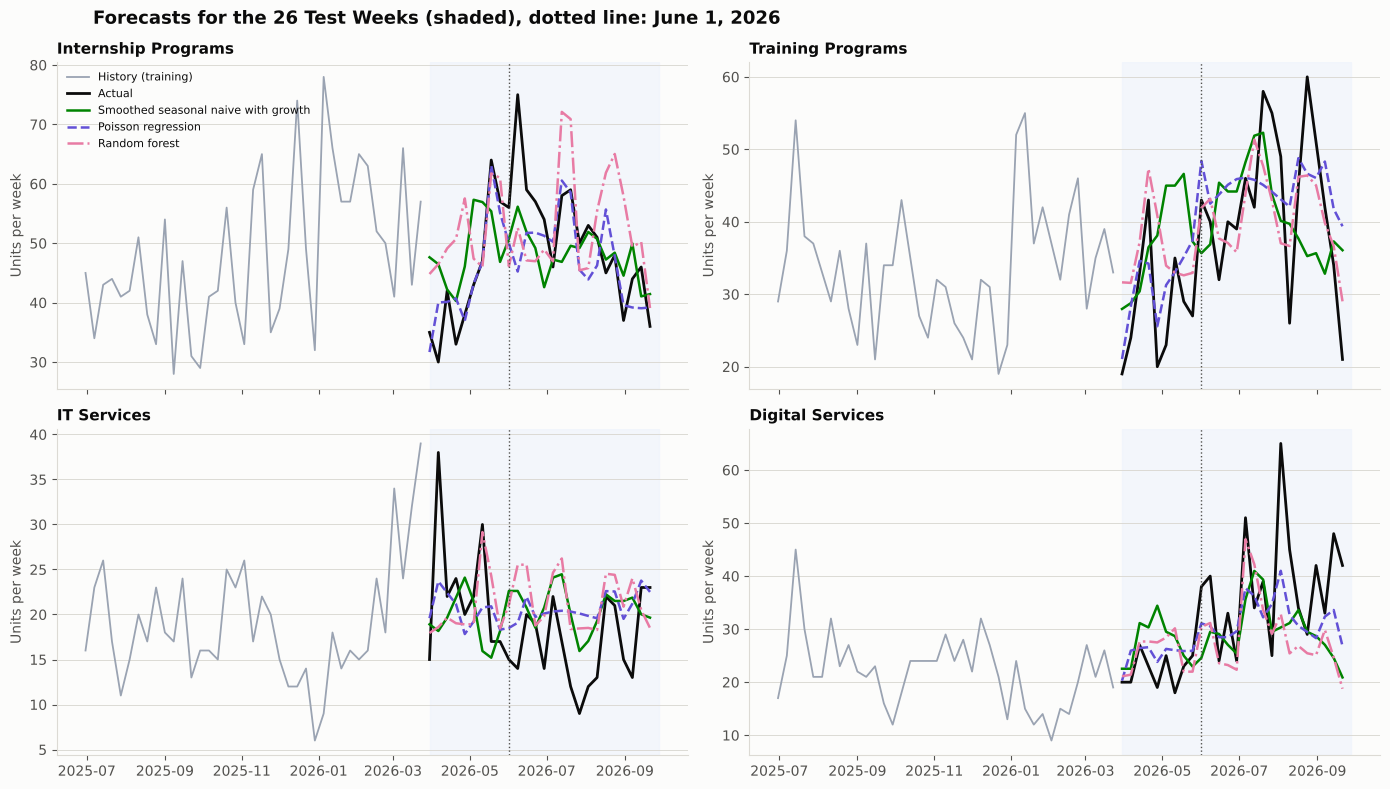

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
show = ["Smoothed seasonal naive with growth", "Poisson regression", "Random forest"]
for ax, line in zip(axes.ravel(), LINES):
    part = results[results["service_line"] == line].set_index("week_start")
    history = frames[line]["y"].iloc[TRAIN_END - 38:TRAIN_END + 1]
    ax.plot(history.index, history, color="#9aa3b2", linewidth=1.3, label="History (training)")
    ax.plot(part.index, part["actual"], color=INK, linewidth=2, label="Actual")
    for method, style in zip(show, ["-", "--", "-."]):
        ax.plot(part.index, part[method], color=MCOLOR[method], linewidth=1.8, linestyle=style, label=method)
    ax.axvline(SHIFT_START, color=INK_SOFT, linestyle=":", linewidth=1)
    ax.axvspan(test_weeks[0], test_weeks[-1] + WEEK, color="#eef3fb", alpha=0.6, zorder=0)
    ax.set_title(line, fontsize=11)
    ax.set_ylabel("Units per week")
    clean_axes(ax)
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Forecasts for the 26 Test Weeks (shaded), dotted line: June 1, 2026", x=0.07, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Forecast Accuracy Evaluation

The same measures as on Day 46: **MAE** (average miss in units per week), **WAPE** (total absolute miss over total demand),
and **bias** (total forecast minus total actual, over total actual; positive means too high).
"All lines" scores the weekly total of the four lines, which is what a company-wide plan uses, but it lets errors of different lines cancel,
so the lines are also scored one by one.

In [10]:
ALL_METHODS = ["Moving average (13 weeks)", "Smoothed seasonal naive with growth", "Holt-Winters", "Poisson regression", "Random forest"]


def score(actual, predicted):
    error = predicted - actual
    return {"MAE": error.abs().mean(), "WAPE_pct": error.abs().sum() / actual.sum() * 100, "bias_pct": error.sum() / actual.sum() * 100}


def score_table(frame):
    rows = []
    for method in ALL_METHODS:
        for line in LINES:
            part = frame[frame["service_line"] == line]
            rows.append({"method": method, "service_line": line, **score(part["actual"], part[method])})
        total = frame.groupby("week_start")[["actual"] + ALL_METHODS].sum()
        rows.append({"method": method, "service_line": "All lines", **score(total["actual"], total[method])})
    return pd.DataFrame(rows)


model_metrics = score_table(results)
wape_table = model_metrics.pivot(index="method", columns="service_line", values="WAPE_pct").loc[ALL_METHODS][LINES + ["All lines"]]
bias_table = model_metrics.pivot(index="method", columns="service_line", values="bias_pct").loc[ALL_METHODS][LINES + ["All lines"]]
print("WAPE (%) over the 26 test weeks, lower is better:")
display(wape_table.round(1))
print("Bias (%) over the 26 test weeks (positive = the forecast was too high):")
display(bias_table.round(1))

# The randomness of the data: how far the regression is from the weeks it was fitted on
noise_level = {}
for line in LINES:
    fitted = fit_regression(frames[line], TRAIN_END, K_BEST).predict(regression_design(frames[line].iloc[:TRAIN_END + 1], K_BEST).to_numpy())
    noise_level[line] = wape(frames[line]["y"].iloc[:TRAIN_END + 1], fitted)
print("WAPE (%) of the regression on the training weeks it was fitted on (random variation that no forecast can remove):")
print({line: round(float(v), 1) for line, v in noise_level.items()})

WAPE (%) over the 26 test weeks, lower is better:


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines
method,,,,,
Moving average (13 weeks),21.1,25.9,26.0,45.9,12.5
Smoothed seasonal naive with growth,14.9,26.7,27.1,26.9,10.3
Holt-Winters,19.9,23.3,27.4,31.2,11.9
Poisson regression,10.5,19.0,23.3,20.7,7.2
Random forest,20.0,18.3,29.0,25.4,10.4


Bias (%) over the 26 test weeks (positive = the forecast was too high):


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines
method,,,,,
Moving average (13 weeks),15.1,2.5,8.4,-45.9,-3.7
Smoothed seasonal naive with growth,-0.4,5.8,7.7,-10.9,-0.1
Holt-Winters,9.6,4.1,4.4,-15.6,1.4
Poisson regression,-3.9,6.9,9.6,-8.9,-0.3
Random forest,8.2,4.4,13.1,-15.0,2.4


WAPE (%) of the regression on the training weeks it was fitted on (random variation that no forecast can remove):
{'Internship Programs': 14.5, 'Training Programs': 17.4, 'IT Services': 20.9, 'Digital Services': 19.9}


**What do the planned campaigns and holidays add?**

The regression knows the plan for the weeks it forecasts, and the baselines and Holt-Winters do not. To see how much of its advantage comes from that knowledge, the same regression is fitted
without the campaign days, without the holidays, and without both, and scored on the validation weeks and on the test weeks (all lines together, and the weekly total).

In [11]:
def regression_variant_scores(origin, drop):
    actual, predicted = [], []
    for line in LINES:
        model = fit_regression(frames[line], origin, K_BEST, drop)
        predicted.append(predict_regression(model, frames[line], origin + 1, HORIZON, K_BEST, drop))
        actual.append(frames[line]["y"].iloc[origin + 1:origin + 1 + HORIZON].to_numpy())
    actual, predicted = np.array(actual), np.array(predicted)
    return wape(actual, predicted), wape(actual.sum(axis=0), predicted.sum(axis=0))


rows = []
for label, drop in [("with campaigns and holidays", ()), ("without the holidays", ("hol",)), ("without the campaign days", ("camp",)), ("without both", ("camp", "hol"))]:
    validation_line, validation_total = regression_variant_scores(VAL_ORIGIN, drop)
    test_line, test_total = regression_variant_scores(TRAIN_END, drop)
    rows.append({"regression": label, "validation WAPE of line-weeks %": validation_line, "validation WAPE of the total %": validation_total,
                 "test WAPE of line-weeks %": test_line, "test WAPE of the total %": test_total})
display(pd.DataFrame(rows).set_index("regression").round(1))

,validation WAPE of line-weeks %,validation WAPE of the total %,test WAPE of line-weeks %,test WAPE of the total %
regression,,,,
with campaigns and holidays,18.3,7.6,17.0,7.2
without the holidays,18.8,9.1,17.6,7.6
without the campaign days,20.3,9.4,20.4,9.9
without both,21.4,11.8,20.9,9.5


**Observation:** Knowing the plan is worth a lot. Without the campaign days and holidays, the error of the regression on the weekly total rises from 7.6% to 11.8% on the validation weeks and from 7.2% to 9.5% on the test weeks, and the error of the line-weeks rises from 18.3% to 21.4% and from 17.0% to 20.9%. The campaign days matter more than the holidays. Without any plan the regression is about as accurate as the best baseline (10.3%) and the random forest (10.4%) on the test total, so its lead over them comes mostly from the information about the plan, not from a better way of describing the history. This also means a forecast is only as good as the campaign calendar given to it.

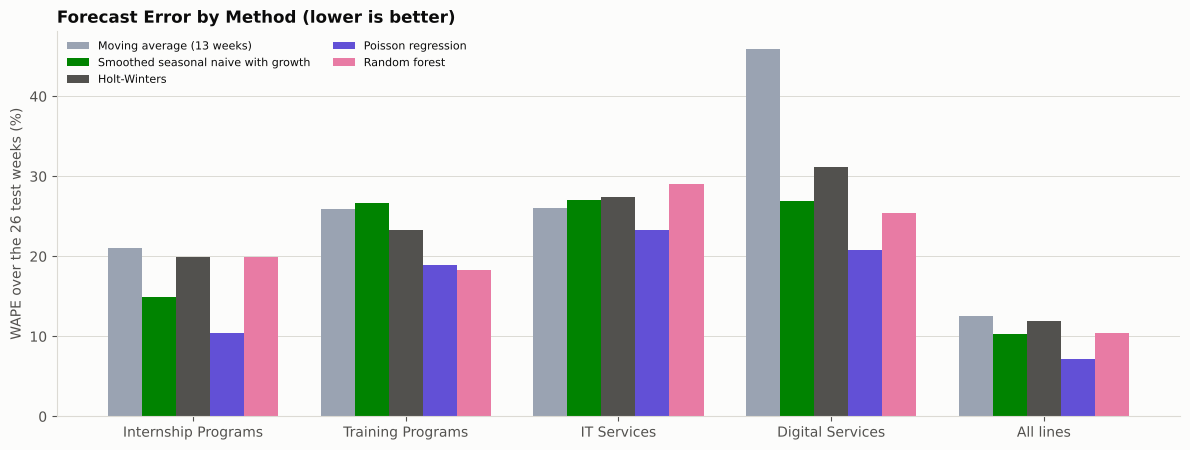

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.6))
groups = LINES + ["All lines"]
width = 0.16
for i, method in enumerate(ALL_METHODS):
    positions = np.arange(len(groups)) + (i - 2) * width
    ax.bar(positions, wape_table.loc[method, groups], width=width, color=MCOLOR[method], label=method)
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels(groups)
ax.set_ylabel("WAPE over the 26 test weeks (%)")
ax.set_title("Forecast Error by Method (lower is better)")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
clean_axes(ax)
plt.tight_layout()
plt.show()

**Observation:** The Poisson regression is the best method in the total (WAPE 7.2%, against 10.3% for the best baseline, 10.4% for the random forest, 11.9% for Holt-Winters, and 12.5% for the 13-week average), with almost no bias (-0.3%). By line it is the best in Internship Programs (10.5%), IT Services (23.3%), and Digital Services (20.7%), and the random forest is slightly better for Training Programs (18.3% against 19.0%). Holt-Winters, which uses only the past of the series, is no better than the baselines, because 130 weeks are only two and a half yearly cycles to learn from. The numbers need two warnings. First, the regression knows the campaign and holiday plan, as shown above. Second, the errors of the lines are close to the randomness of the data: the regression is off by 14.5% to 20.9% even on the weeks it was fitted on, so the 10.5% of Internship Programs is better than the randomness suggests and probably partly luck of these 26 weeks, while 19% to 23% for the other lines is close to the limit. Digital Services is under-forecast by every method (from -8.9% for the regression to -15.6% for Holt-Winters), because none of them knows about the lift after June 1.

**Before and after the change in the last months, and how far ahead**

The test weeks before June 1 look like the history, and the weeks from June 1 contain the lift of Digital Services and the slowdown of IT Services.
The error is also compared by how far ahead the forecast looks.

In [13]:
rows = []
for period, mask in [("March 30 to May 31 (9 weeks)", ~results["after_shift"]), ("June 1 to September 27 (17 weeks)", results["after_shift"])]:
    part = results[mask]
    total = part.groupby("week_start")[["actual"] + ALL_METHODS].sum()
    for method in ALL_METHODS:
        by_line = [wape(part[part["service_line"] == line]["actual"], part[part["service_line"] == line][method]) for line in LINES]
        rows.append({"period": period, "method": method, "WAPE of the total %": wape(total["actual"], total[method]),
                     "average WAPE of the 4 lines %": np.mean(by_line)})
period_table = pd.DataFrame(rows)
print("WAPE (%) by period:")
display(period_table.pivot(index="method", columns="period", values=["WAPE of the total %", "average WAPE of the 4 lines %"]).loc[ALL_METHODS].round(1))

buckets = pd.cut(results["horizon"], [0, 8, 17, 26], labels=["weeks 1-8", "weeks 9-17", "weeks 18-26"])
horizon_table = results.groupby(buckets, observed=True).apply(lambda part: pd.Series({m: wape(part["actual"], part[m]) for m in ALL_METHODS}))
print("WAPE (%) of all line-weeks by how far ahead the forecast looks:")
display(horizon_table.T.round(1))

WAPE (%) by period:


WAPE of the total %                                  average WAPE of the 4 lines %                             
period                              June 1 to September 27 (17 weeks) March 30 to May 31 (9 weeks) June 1 to September 27 (17 weeks) March 30 to May 31 (9 weeks)
method                                                                                                                                                           
Moving average (13 weeks)                                        11.9                         13.9                              29.6                         29.5
Smoothed seasonal naive with growth                               8.6                         14.4                              22.5                         28.1
Holt-Winters                                                      9.7                         17.2                              23.5                         29.9
Poisson regression                                                8.1                          4.8                              19.8                         15.2
Random forest                                                     8.7                         14.5                              24.1                         22.2

WAPE (%) of all line-weeks by how far ahead the forecast looks:


horizon,weeks 1-8,weeks 9-17,weeks 18-26
Moving average (13 weeks),32.5,21.1,34.5
Smoothed seasonal naive with growth,28.9,18.4,22.6
Holt-Winters,33.1,18.5,24.7
Poisson regression,14.3,15.3,20.6
Random forest,23.8,17.2,25.7


**Observation:** The advantage of the regression is concentrated before June. From March 30 to May 31 its error on the total is 4.8%, against 13.9% to 17.2% for the other methods, because spring 2026 had about half the campaign days of spring 2025 in Internship Programs (11 against 22) and Training Programs (13 against 24), and the methods that copy last year over-forecast; the regression was told the real plan. From June 1, when the change in Digital Services and IT Services starts, the methods are much closer: 8.1% for the regression, 8.6% for the best baseline, and 8.7% for the random forest on the total, and 19.8% against 22.5% and 24.1% averaged over the four lines. No method can foresee a change that is not in its history, which is the main limit of forecasting from history. By how far ahead the forecast looks, the regression is best in the first 8 weeks (14.3%) and its error rises to 20.6% in weeks 18 to 26, when the changed demand has fully arrived; the lead over the random forest and the baseline is smallest in weeks 9 to 17 (15.3% against 17.2% and 18.4%).

**What the random forest uses**

The importance of a feature is how much it reduces the error of the trees that use it (the groups below add the importance of the sine and cosine waves, and of the four lines).

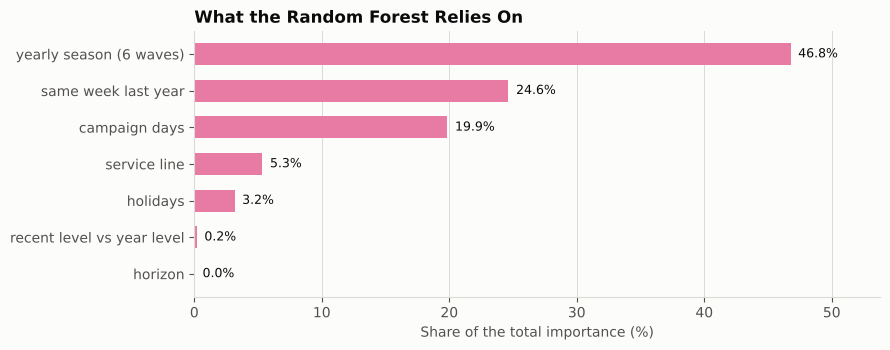

In [14]:
forest_final = fit_forest(TRAIN_END, RF_BEST)
importance = pd.Series(forest_final.feature_importances_, index=FEATURES)
grouped = pd.Series({"horizon": importance["horizon"], "recent level vs year level": importance["recent vs year"],
                     "same week last year": importance["same week last year"], "campaign days": importance["campaign days"],
                     "holidays": importance["holidays"], "yearly season (6 waves)": importance[[f for f in FEATURES if f.startswith("season")]].sum(),
                     "service line": importance[[f for f in FEATURES if f.startswith("line")]].sum()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(grouped.index, grouped.values * 100, color="#e87ba4", height=0.6)
for position, value in enumerate(grouped.values):
    ax.text(value * 100 + 0.6, position, f"{value * 100:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Share of the total importance (%)")
ax.set_title("What the Random Forest Relies On")
ax.set_xlim(0, grouped.max() * 100 * 1.15)
clean_axes(ax, "x")
plt.tight_layout()
plt.show()

**Observation:** The forest relies on the yearly season (46.8% of the importance), the same week of last year (24.6%), and the campaign days (19.9%), while the recent level against the year level has almost no weight (0.2%) and the horizon none (0.0%). This explains its behavior: it knows the calendar and the plan, but it hardly looks at whether demand has recently moved away from its yearly average, so it follows the old pattern after the change and under-forecasts Digital Services by 15.0%.

## 8. How Sure Is the Forecast? Prediction Ranges

A single number hides the uncertainty. A simple and honest range comes from the past errors of the selected model: the ratio `actual / forecast` of
each line is collected on the **validation weeks** (which the model had not seen either), and its 10th and 90th percentiles are applied to the forecast, which
gives a range that should contain about 80% of the weeks. The range is then checked on the test weeks.

In [15]:
def selected_forecast(forecast_dict):
    return forecast_dict[SELECTED]


def ratio_quantiles(actual, forecast):
    ratios = {}
    for i, line in enumerate(LINES):
        a, f = actual[i * HORIZON:(i + 1) * HORIZON], forecast[i * HORIZON:(i + 1) * HORIZON]
        ratios[line] = np.quantile(a / f, [0.10, 0.90])
    return ratios


validation_ratios = ratio_quantiles(validation_actual, selected_forecast(validation_forecasts))
results["range_low"] = [selected_forecast(test_forecasts)[i] * validation_ratios[line][0] for i, line in enumerate(np.repeat(LINES, HORIZON))]
results["range_high"] = [selected_forecast(test_forecasts)[i] * validation_ratios[line][1] for i, line in enumerate(np.repeat(LINES, HORIZON))]
results["inside_range"] = (results["actual"] >= results["range_low"]) & (results["actual"] <= results["range_high"])

coverage = pd.DataFrame({"ratio at the 10th percentile": {line: validation_ratios[line][0] for line in LINES},
                         "ratio at the 90th percentile": {line: validation_ratios[line][1] for line in LINES},
                         "weeks inside the range, March 30 to May 31 (%)": results[~results["after_shift"]].groupby("service_line")["inside_range"].mean().mul(100),
                         "weeks inside the range, June 1 to Sept 27 (%)": results[results["after_shift"]].groupby("service_line")["inside_range"].mean().mul(100),
                         "weeks inside the range, all 26 (%)": results.groupby("service_line")["inside_range"].mean().mul(100)}).loc[LINES]
print("Selected model:", SELECTED, "| range = forecast x the 10th and 90th percentile of the ratio actual / forecast on the validation weeks")
display(coverage.round(2))
print("Share of all 104 line-weeks inside the range:", round(float(results["inside_range"].mean() * 100), 1), "% (the range was built to contain about 80%)")

Selected model: Poisson regression | range = forecast x the 10th and 90th percentile of the ratio actual / forecast on the validation weeks


,ratio at the 10th percentile,ratio at the 90th percentile,"weeks inside the range, March 30 to May 31 (%)","weeks inside the range, June 1 to Sept 27 (%)","weeks inside the range, all 26 (%)"
Internship Programs,0.87,1.32,77.78,88.24,84.62
Training Programs,0.81,1.30,66.67,82.35,76.92
IT Services,0.63,1.30,77.78,76.47,76.92
Digital Services,0.67,1.22,100.00,52.94,69.23


Share of all 104 line-weeks inside the range: 76.9 % (the range was built to contain about 80%)


**Observation:** A range built from the validation errors should contain about 80% of the weeks, and it contains 76.9% of the 104 test line-weeks, so the width is about right for normal weeks. It works before the change (66.7% to 100% of the weeks by line from March 30 to May 31) and fails where the level moved: only 52.9% of the Digital Services weeks from June 1 are inside, because the actual values rise above the top of the range. A range that comes from past errors describes ordinary randomness and cannot cover a change in the pattern.

## 9. Forecast of the Next 26 Weeks (October 2026 to March 2027)

The models are refitted on **all 156 weeks** and forecast the 26 weeks after the end of the data. The campaign days of the future weeks
are assumed to be the typical load of the last 52 weeks, and the holidays are the fixed dates of the calendar.
The range uses the ratios of the out-of-sample forecasts of the **validation and the test weeks together** (52 weeks per line, which include the change of June 2026), so it is wider and more honest than the one built on the validation alone.

**A level check before trusting the regression.** The regression describes demand as a smooth trend plus a yearly pattern. If a line has changed
level recently (like Digital Services and IT Services on Day 46), the model's level is stale. A simple remedy is to
multiply the forecast of a line by the **ratio of its actual demand to the model's fitted demand over the last 13 weeks**. Its price is that it also
follows noise, so it is first tried on past forecasts, at five different starting weeks, where no change happened.

In [16]:
def regression_backtest(origin, window=13):
    """WAPE of all line-weeks for the plain regression and for the regression multiplied by its recent actual / fitted ratio."""
    plain_error = adjusted_error = total = 0.0
    for line in LINES:
        frame = frames[line]
        model = fit_regression(frame, origin, K_BEST)
        fitted = model.predict(regression_design(frame.iloc[:origin + 1], K_BEST).to_numpy())
        ratio = frame["y"].iloc[origin - window + 1:origin + 1].sum() / fitted[-window:].sum()
        forecast = predict_regression(model, frame, origin + 1, HORIZON, K_BEST)
        actual = frame["y"].iloc[origin + 1:origin + 1 + HORIZON].to_numpy()
        plain_error += np.abs(forecast - actual).sum()
        adjusted_error += np.abs(forecast * ratio - actual).sum()
        total += actual.sum()
    return plain_error / total * 100, adjusted_error / total * 100


rows = []
for origin in (77, 90, 103, 116, 129):
    plain_wape, adjusted_wape = regression_backtest(origin)
    rows.append({"forecast starts after": all_weeks[origin].date(), "plain regression WAPE %": plain_wape, "with level correction WAPE %": adjusted_wape})
backtest = pd.DataFrame(rows).set_index("forecast starts after")
backtest.loc["average"] = backtest.mean()
display(backtest.round(1))

,plain regression WAPE %,with level correction WAPE %
forecast starts after,,
2025-03-24,18.9,20.1
2025-06-23,20.6,21.1
2025-09-22,18.3,17.7
2025-12-22,17.7,17.2
2026-03-23,17.0,18.7
average,18.5,19.0


**Observation:** The correction does not pay off when nothing has changed: it lowers the error at two of the five starting weeks (18.3% to 17.7% and 17.7% to 17.2%) and raises it at the other three, and on average it costs half a point (19.0% against 18.5%). It is used for the future forecast only because it is the cheap protection against a stale level, and the ratios below show where it matters. Be aware that its benefit after a real change cannot be tested on a future that has not happened yet, so the forecast without the correction is saved next to it.

In [17]:
LAST = N_HISTORY - 1
future_weeks = all_weeks[N_HISTORY:]
future = {"Holt-Winters": [], "Poisson regression": []}
for line in LINES:
    future["Holt-Winters"].append(holt_winters_forecast(frames[line], LAST, HORIZON))
    future["Poisson regression"].append(predict_regression(fit_regression(frames[line], LAST, K_BEST), frames[line], LAST + 1, HORIZON, K_BEST))
future = {name: np.concatenate(values) for name, values in future.items()}
future["Random forest"] = forest_forecast(fit_forest(LAST, RF_BEST), LAST)

val_forecast, test_forecast = selected_forecast(validation_forecasts), selected_forecast(test_forecasts)
future_ratios = {}
for i, line in enumerate(LINES):
    a = np.concatenate([validation_actual[i * HORIZON:(i + 1) * HORIZON], actual_values(TRAIN_END)[i * HORIZON:(i + 1) * HORIZON]])
    f = np.concatenate([val_forecast[i * HORIZON:(i + 1) * HORIZON], test_forecast[i * HORIZON:(i + 1) * HORIZON]])
    future_ratios[line] = np.quantile(a / f, [0.10, 0.90])

# Recent level of every line against the regression fitted on all the history
recent_ratio = {}
for line in LINES:
    model = fit_regression(frames[line], LAST, K_BEST)
    fitted = model.predict(regression_design(frames[line].iloc[:LAST + 1], K_BEST).to_numpy())
    recent_ratio[line] = frames[line]["y"].iloc[LAST - 12:LAST + 1].sum() / fitted[-13:].sum()
print("Actual demand of the last 13 weeks divided by what the regression fitted on all the history expects for them:")
print({line: round(float(v), 2) for line, v in recent_ratio.items()})

future_table = pd.DataFrame({"week_start": np.tile(future_weeks, 4), "service_line": np.repeat(LINES, HORIZON)})
for name, values in future.items():
    future_table[name] = values
future_table["model_forecast"] = future[SELECTED]
future_table["level_correction"] = [recent_ratio[line] for line in future_table["service_line"]]
future_table["forecast"] = future_table["model_forecast"] * future_table["level_correction"]
future_table["range_low"] = [future_table["forecast"].iloc[i] * future_ratios[line][0] for i, line in enumerate(future_table["service_line"])]
future_table["range_high"] = [future_table["forecast"].iloc[i] * future_ratios[line][1] for i, line in enumerate(future_table["service_line"])]
future_table["campaign_days_assumed"] = np.concatenate([frames[line]["camp"].iloc[N_HISTORY:].to_numpy() for line in LINES])
future_table["holidays_in_week"] = np.concatenate([frames[line]["hol"].iloc[N_HISTORY:].to_numpy() for line in LINES])

# Plan month = the month of the Thursday of the week, so each of the 26 weeks belongs to exactly one month (months have 4 or 5 weeks)
future_table["month"] = (future_table["week_start"] + pd.Timedelta(days=3)).dt.to_period("M").astype(str)
monthly_plan = future_table.pivot_table(index="month", columns="service_line", values="forecast", aggfunc="sum")[LINES]
monthly_plan["All lines"] = monthly_plan.sum(axis=1)
monthly_plan["weeks"] = future_table[future_table["service_line"] == LINES[0]].groupby("month").size()
print(f"Forecast of the selected model ({SELECTED}) with the level correction, units per plan month (the month of the Thursday of each week, so months have 4 or 5 weeks):")
display(monthly_plan.round(0).astype(int))
print("The same, in units per week (the fair way to compare months of different length):")
display(monthly_plan[LINES + ["All lines"]].div(monthly_plan["weeks"], axis=0).round(1))

same_period = pd.DataFrame({line: [frames[line]["y"].iloc[N_HISTORY - 52:N_HISTORY - 26].sum(), frames[line]["y"].iloc[N_HISTORY - 26:N_HISTORY].sum(),
                                   future_table[future_table["service_line"] == line]["model_forecast"].sum(), future_table[future_table["service_line"] == line]["forecast"].sum()]
                            for line in LINES},
                           index=["actual, the same 26 weeks a year earlier (Sep 2025-Mar 2026)", "actual, the latest 26 weeks (Mar-Sep 2026)",
                                  "forecast without correction, next 26 weeks", "forecast with level correction, next 26 weeks"]).T
print("Units in 26 weeks:")
display(same_period.round(0).astype(int))

Actual demand of the last 13 weeks divided by what the regression fitted on all the history expects for them:
{'Internship Programs': 1.0, 'Training Programs': 1.0, 'IT Services': 0.88, 'Digital Services': 1.07}
Forecast of the selected model (Poisson regression) with the level correction, units per plan month (the month of the Thursday of each week, so months have 4 or 5 weeks):


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines,weeks
month,,,,,,
2026-10,222,185,97,165,669,5
2026-11,202,151,75,139,567,4
2026-12,262,163,62,142,629,5
2027-01,268,167,59,103,596,4
2027-02,253,169,79,105,607,4
2027-03,202,144,93,124,562,4


The same, in units per week (the fair way to compare months of different length):


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines
month,,,,,
2026-10,44.5,37.0,19.4,33.0,133.8
2026-11,50.5,37.9,18.7,34.8,141.8
2026-12,52.4,32.5,12.5,28.5,125.9
2027-01,67.1,41.7,14.6,25.7,149.1
2027-02,63.4,42.3,19.9,26.3,151.8
2027-03,50.4,35.9,23.3,31.0,140.6


Units in 26 weeks:


,"actual, the same 26 weeks a year earlier (Sep 2025-Mar 2026)","actual, the latest 26 weeks (Mar-Sep 2026)","forecast without correction, next 26 weeks","forecast with level correction, next 26 weeks"
Internship Programs,1338,1263,1415,1410
Training Programs,879,976,980,979
IT Services,498,489,529,465
Digital Services,538,846,726,778


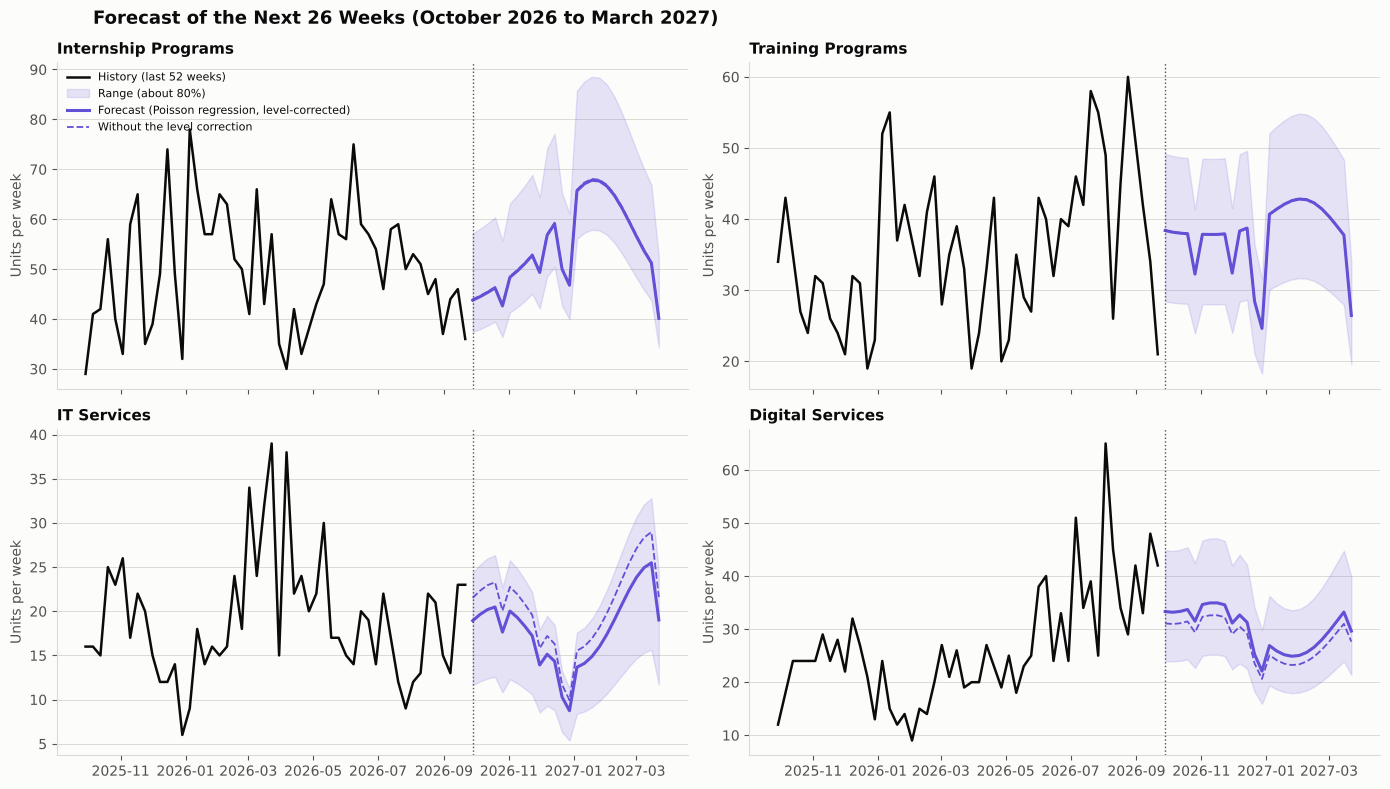

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, line in zip(axes.ravel(), LINES):
    part = future_table[future_table["service_line"] == line].set_index("week_start")
    history = frames[line]["y"].iloc[N_HISTORY - 52:N_HISTORY]
    ax.plot(history.index, history, color=INK, linewidth=1.8, label="History (last 52 weeks)")
    ax.fill_between(part.index, part["range_low"], part["range_high"], color=MCOLOR[SELECTED], alpha=0.15, label="Range (about 80%)")
    ax.plot(part.index, part["forecast"], color=MCOLOR[SELECTED], linewidth=2.2, label=f"Forecast ({SELECTED}, level-corrected)")
    ax.plot(part.index, part["model_forecast"], color=MCOLOR[SELECTED], linewidth=1.3, linestyle="--", label="Without the level correction")
    ax.axvline(future_weeks[0], color=INK_SOFT, linestyle=":", linewidth=1)
    ax.set_title(line, fontsize=11)
    ax.set_ylabel("Units per week")
    clean_axes(ax)
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Forecast of the Next 26 Weeks (October 2026 to March 2027)", x=0.07, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observation:** The last 13 weeks of Internship Programs and Training Programs are exactly what the regression expects (ratio 1.00), so they are not corrected. IT Services runs 12% below the model (0.88) and Digital Services 7% above it (1.07), so the first is lowered and the second is raised. The corrected forecast for the next 26 weeks is 1,410 units for Internship Programs (5% more than the same weeks a year earlier), 979 for Training Programs (+11%), 465 for IT Services (-7%), and 778 for Digital Services (+45%, the lift of June 2026 on top of the growth). Counted per week (months have four or five weeks), all lines are busiest in January and February (about 149 and 152 units a week, led by Internship Programs with 63 to 67), lowest in December (about 126, because of the holidays), and in between in the other months (134 to 142). These are plans under the assumption that campaigns run at the typical load of the last year and that no new change in the pattern happens. The ranges are wide (the weekly ranges of Digital Services add up to 561 to 1,049 units over the 26 weeks, a rough upper bound on the width of the range of the total), which is the honest size of the uncertainty.

## 10. Save the Results

In [19]:
validation_out = validation_table.copy()
validation_out.index.name = "method"
validation_out.round(2).to_csv(DATA_DIR / "forecasts" / "model_validation.csv")

test_out = results.copy()
test_out["week_start"] = test_out["week_start"].dt.strftime("%Y-%m-%d")
test_out.round(2).to_csv(DATA_DIR / "forecasts" / "model_forecasts_test.csv", index=False)

model_metrics.round(2).to_csv(DATA_DIR / "forecasts" / "model_metrics.csv", index=False)

future_out = future_table.drop(columns=["month"]).copy()
future_out["week_start"] = future_out["week_start"].dt.strftime("%Y-%m-%d")
future_out["selected_model"] = SELECTED
future_out.round(2).to_csv(DATA_DIR / "forecasts" / "future_demand_forecast_weekly.csv", index=False)

print("Saved in", DATA_DIR / "forecasts")
print("  model_validation.csv                  rows:", len(validation_out), "(candidates on the validation weeks)")
print("  model_forecasts_test.csv              rows:", len(test_out), "(26 test weeks x 4 lines, all methods and the range)")
print("  model_metrics.csv                     rows:", len(model_metrics), "(MAE, WAPE, bias by method and line)")
print("  future_demand_forecast_weekly.csv     rows:", len(future_out), "(next 26 weeks x 4 lines, with range)")
print("Selected model:", SELECTED)

Saved in ../datasets/veda_demand/forecasts
  model_validation.csv                  rows: 5 (candidates on the validation weeks)
  model_forecasts_test.csv              rows: 104 (26 test weeks x 4 lines, all methods and the range)
  model_metrics.csv                     rows: 25 (MAE, WAPE, bias by method and line)
  future_demand_forecast_weekly.csv     rows: 104 (next 26 weeks x 4 lines, with range)
Selected model: Poisson regression


## Outcome

Both a statistical and a machine-learning model were built, selected on a validation period inside the training data, and tested once on the 26 test weeks of Day 46. The Poisson regression (trend, yearly season, campaign days, and holidays) was the best, with a WAPE of 7.2% on the weekly total and 10.5% to 23.3% by line, against 10.3% for the best baseline of Day 46. Holt-Winters did not beat the baselines, and the random forest was about as accurate as the best baseline in total but better for Training Programs. Most of the regression's advantage comes from knowing the planned campaigns and holidays: without them, its error on the test total rises from 7.2% to 9.5%. After June 1 the advantage mostly disappears, since no model could foresee the lift in Digital Services and the slowdown in IT Services, and the 80% ranges cover only 52.9% of the Digital Services weeks in that period. I also saved a forecast for the next 26 weeks with ranges, and a level correction (it costs about half a point on average, but protects against a stale level) next to the plain forecast. Day 48 uses these files to build the future demand dashboard and the business planning recommendations, and to explain why a trend learned from history can fail.